# Combined Unintegrated Data

- **Purpose:** Check the shared gene space and the structure of the combined tumor and cell line object before integration.
- **Inputs:** `data/processed/preprocessed_tumor.h5ad`, `data/processed/preprocessed_cell_line.h5ad`.
- **Outputs:** Gene-QC and composition plots shown in the notebook.
- **Status:** Exploratory; superseded by the `2_eda` notebooks for the final figures.


In [1]:
import pandas as pd
import numpy as np
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt

import scvi
import os

In [2]:
DATA_DIR = os.path.join("..", "..", "data")
PROCESSED_DIR = os.path.join(DATA_DIR, "processed")

tumor_path = os.path.join(PROCESSED_DIR, "pp_tumor.h5ad")
cell_line_path = os.path.join(PROCESSED_DIR, "pp_cell_line.h5ad")

In [3]:
import torch 
torch.set_float32_matmul_precision("high")

# Concat the adatas

In [4]:
adata_tumor = ad.read_h5ad(tumor_path)
adata_cell_line = ad.read_h5ad(cell_line_path)

adata_tumor.var.index.isin(adata_cell_line.var.index).sum()

np.int64(28617)

In [5]:
adata = ad.concat(
    [adata_cell_line, adata_tumor],
    label="dataset",
    keys=["cell_line", "tumor"],
    join="outer",
)

In [6]:
adata

AnnData object with n_obs × n_vars = 110293 × 28617
    obs: 'cell_id', 'pool_id', 'cell_line', 'mmr_status', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'outlier_qc', 'n_genes', 'doublet_score', 'predicted_doublet', 'outlier', 'chemistry', 'donor_id', 'biosample_id', 'label', 'cell_type', 'mlh1_status', 'sex', 'tissue_site', 'pathological_stage', 'tumor_grade', 'c_value', 'dataset'
    layers: 'counts'

In [7]:
adata.obs.head(3)

,cell_id,pool_id,cell_line,mmr_status,batch,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,outlier_qc,...,biosample_id,label,cell_type,mlh1_status,sex,tissue_site,pathological_stage,tumor_grade,c_value,dataset
AATCCAGGTTTAGGAA-1-18,AATCCAGGTTTAGGAA-1-18,18,NCIH747,MMRp,18,2518,9586,998,10.411016,False,...,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,cell_line
ACATCAGTCATGGTCA-1-18,ACATCAGTCATGGTCA-1-18,18,NCIH747,MMRp,18,3728,16064,1064,6.623506,False,...,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,cell_line
ATCATGGTCGCATGAT-1-18,ATCATGGTCGCATGAT-1-18,18,NCIH747,MMRp,18,3765,18786,985,5.243266,False,...,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,cell_line


In [8]:
adata.var["gene_symbol"] = adata.var.index
adata.var.head(3)

,gene_symbol
A1BG,A1BG
A1BG-AS1,A1BG-AS1
A1CF,A1CF


# Prepare the combined data

## Plot gene metrics

In [9]:
adata.layers["counts"] = adata.X.copy()

adata.var["mt"] = adata.var_names.str.startswith(("MT-", "mt-"))
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=True, inplace=True)

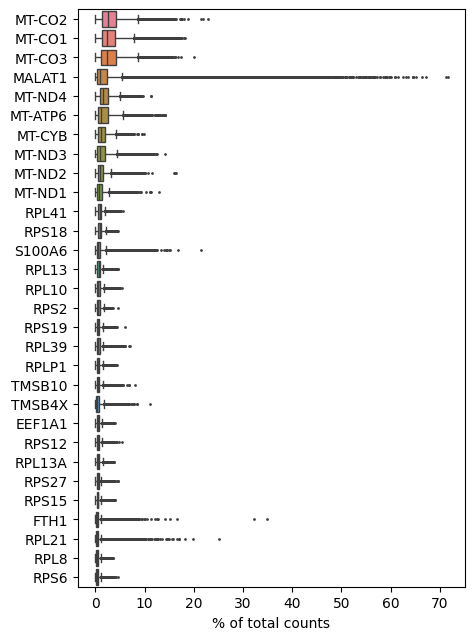

In [10]:
sc.pl.highest_expr_genes(adata)

The usual suspects are present in the highest expressed genes:
- Mitochondrial genes (MT-)
- MALAT1
- Ribosomal protein (RP).
- Actin (TMSB10, TMSB4X)

Characteristics of the other highly expressed genes: 
- S100A6: involved in proliferation, differentiation and is often overexpressed in various cancers
- EEF1A1: responsible for the delivery of tRNA to the ribosome
- FTH1: responsible for storing and detoxifying iron 

Although we have two datasets present in the highest expressed genes shown here, we take a look at the plot with care. As most of the cells are from the tumors we can not say anything about the cell lines and their gene expressions itself. These gene expressions mostly consist of the tumor epiT cells. 

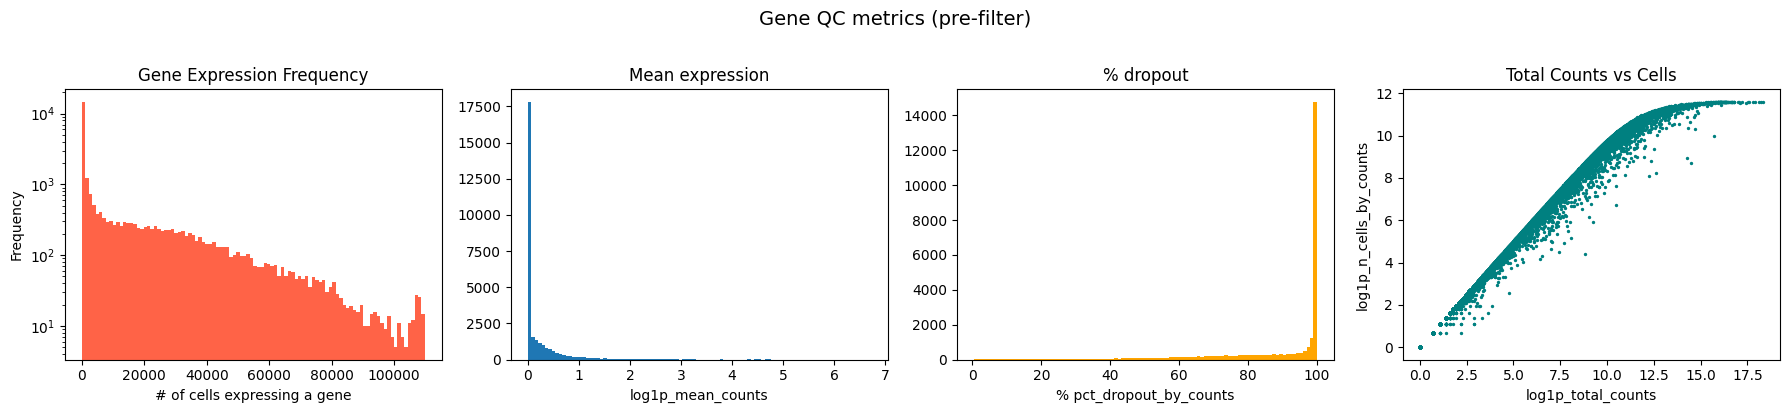

Total genes: 28,617
  rm n_cells < 3: 4,412
  rm total_counts < 15: 6,838
  rm pct_dropout > 99%: 14,759
Number of remaning genes: 21,338


In [11]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
fig.suptitle("Gene QC metrics (pre-filter)", fontsize=14, y=1.02)

axes[0].hist(adata.var["n_cells_by_counts"], bins=100, color="tomato")
axes[0].set_yscale("log")
axes[0].set_title("Gene Expression Frequency")
axes[0].set_xlabel("# of cells expressing a gene")
axes[0].set_ylabel("Frequency")

axes[1].hist(adata.var["log1p_mean_counts"], bins=100)
axes[1].set_xlabel("log1p_mean_counts")
axes[1].set_title("Mean expression")

axes[2].hist(adata.var["pct_dropout_by_counts"], bins=100, color="orange")
axes[2].set_xlabel("% pct_dropout_by_counts")
axes[2].set_title("% dropout")

axes[3].scatter(adata.var["log1p_total_counts"], np.log1p(adata.var["n_cells_by_counts"]), s=2, color="teal")
axes[3].set_xlabel("log1p_total_counts")
axes[3].set_ylabel("log1p_n_cells_by_counts")
axes[3].set_title("Total Counts vs Cells")

plt.tight_layout()

if not os.path.exists("fig"):
    os.makedirs("fig")
gene_qc_fig_path = os.path.join("fig", "gene_qc_plots.pdf")
plt.savefig(gene_qc_fig_path, bbox_inches="tight")
plt.show()


MIN_CELLS       = 3
MIN_TOTAL_COUNTS = 15 
MAX_PCT_DROPOUT  = 99 

n_total = adata.n_vars
print(f"Total genes: {n_total:,}")
print(f"  rm n_cells < {MIN_CELLS:,}: {(adata.var['n_cells_by_counts'] < MIN_CELLS).sum():,}")
print(f"  rm total_counts < {MIN_TOTAL_COUNTS}: {(adata.var['total_counts'] < MIN_TOTAL_COUNTS).sum():,}")
print(f"  rm pct_dropout > {MAX_PCT_DROPOUT}%: {(adata.var['pct_dropout_by_counts'] > MAX_PCT_DROPOUT).sum():,}")

sc.pp.filter_genes(adata, min_cells=3)
sc.pp.filter_genes(adata, min_counts=20)
print(f"Number of remaning genes: {adata.n_vars:,}")

# Visualizations

In [12]:
#adata.layers["counts"] = adata.X.copy() #already done beforehand

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata

sc.pp.highly_variable_genes(
    adata,
    n_top_genes=10000,
    subset=True,
    layer="counts",
    flavor="seurat_v3",
    batch_key="batch"
)

scvi.model.SCVI.setup_anndata(
    adata,
    layer="counts",
    #batch_key="batch",
    categorical_covariate_keys=["batch", "dataset", "chemistry"]
)

In [13]:
model = scvi.model.SCVI(adata)
model

SCVI model with the following parameters: 
n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb, 
latent_distribution: normal.
Training status: Not Trained
Model's adata is minified?: False

In [14]:
model.train(
    early_stopping=True,
    max_epochs=400
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/mnt/bigdisk/markus/miniconda3/envs/scvi-env/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/mnt/bigdisk/markus/miniconda3/envs/scvi-env/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to i

Training:   0%|          | 0/400 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=400` reached.


In [15]:
latent = model.get_latent_representation()
adata.obsm["X_scVI"] = latent
latent.shape

(110293, 10)

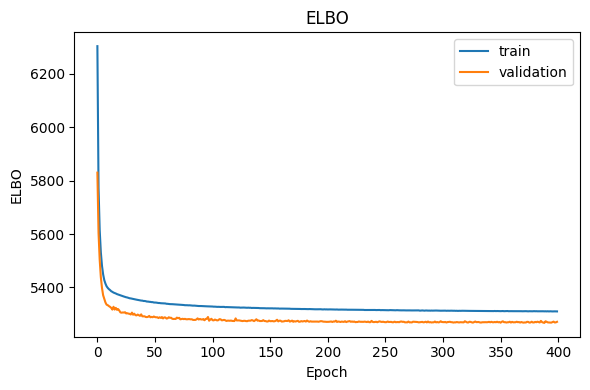

In [32]:
hist = model.history

def plot_metric(train_key, val_key, title, ylabel):
    plt.figure(figsize=(6, 4))
    plt.plot(hist[train_key], label="train")
    plt.plot(hist[val_key], label="validation")
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

if "elbo_train" in hist:
    plot_metric("elbo_train", "elbo_validation", "ELBO", "ELBO")


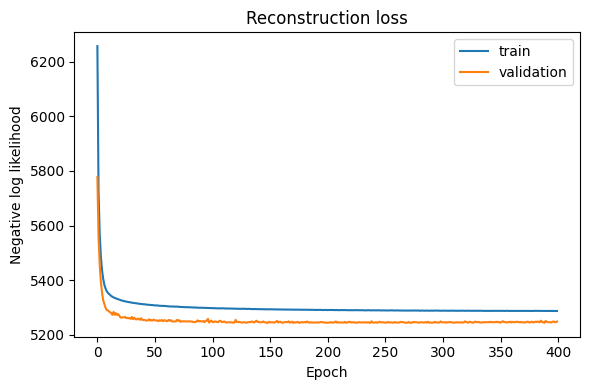

In [33]:
plot_metric(
    "reconstruction_loss_train",
    "reconstruction_loss_validation",
    "Reconstruction loss",
    "Negative log likelihood",
)

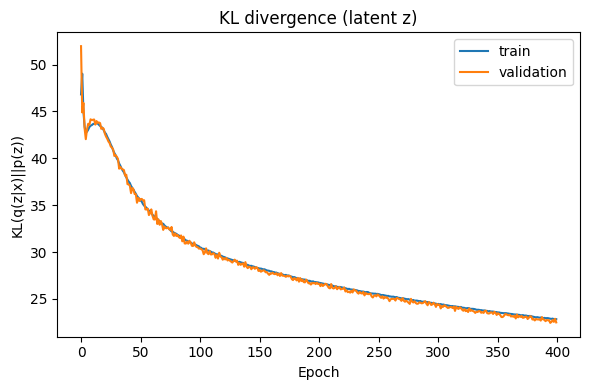

In [34]:
plot_metric(
    "kl_local_train", "kl_local_validation", "KL divergence (latent z)", "KL(q(z|x)||p(z))"
)

## Visualizations without batch correction (PCA)

In [16]:
sc.tl.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

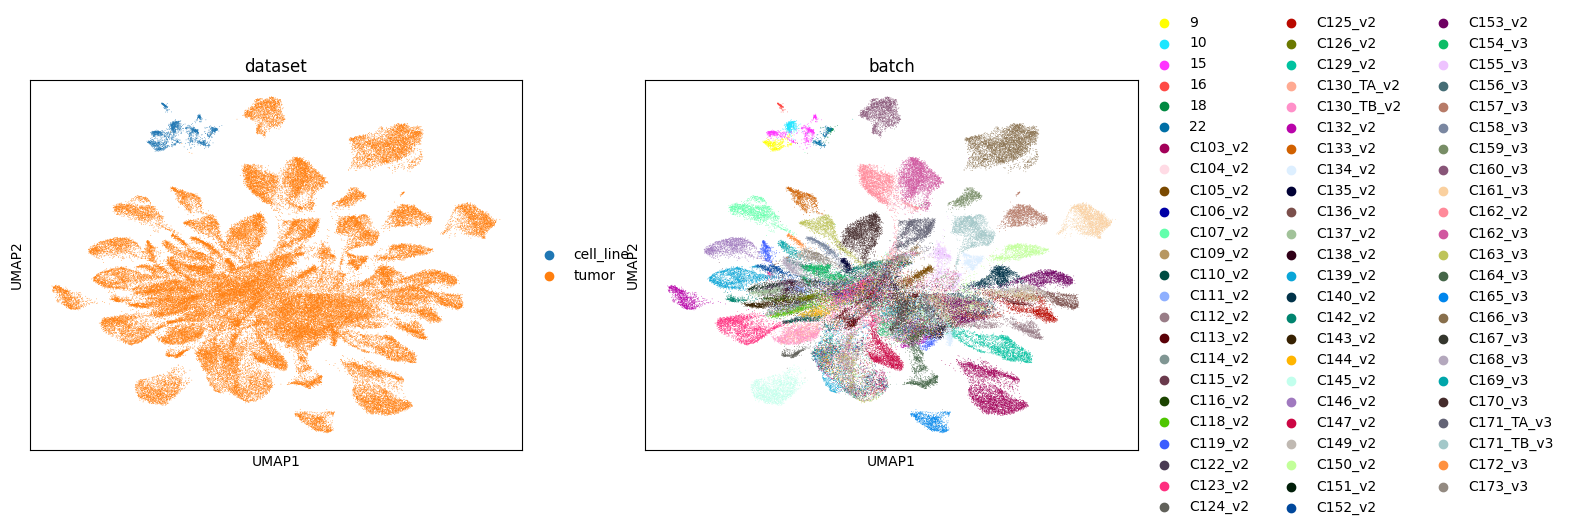

In [17]:
sc.pl.umap(adata, color=["dataset", "batch"])

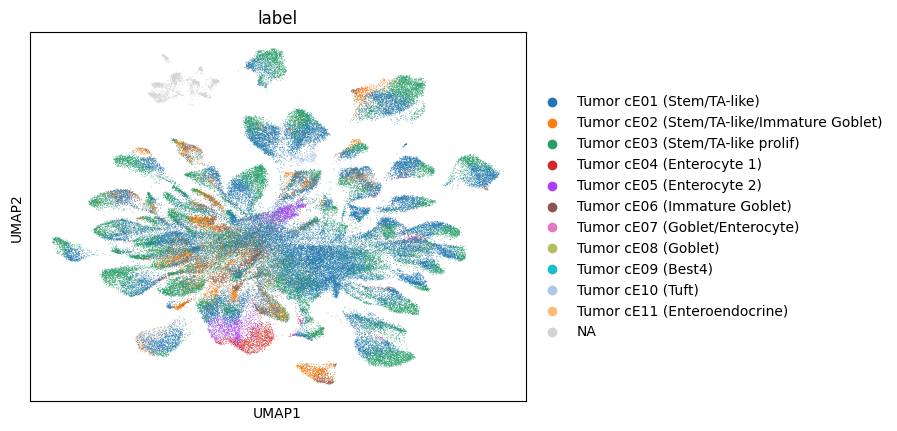

In [18]:
sc.pl.umap(adata, color="label")

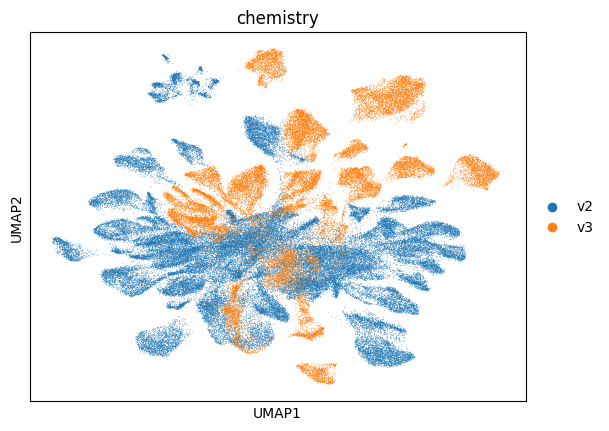

In [19]:
sc.pl.umap(adata, color="chemistry")

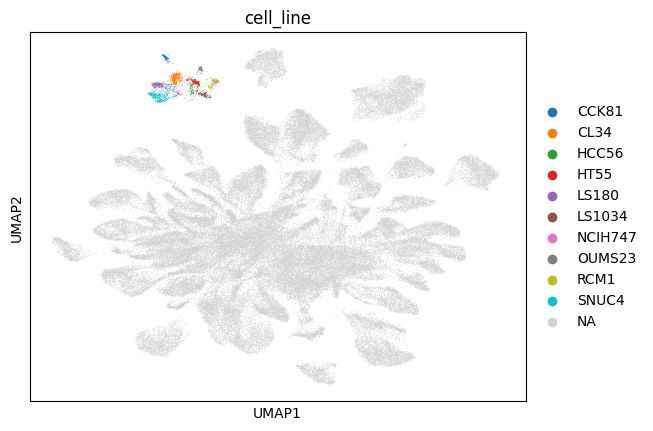

In [20]:
sc.pl.umap(adata, color="cell_line")

## Visualizations with batch correction (scVI)

In [21]:
sc.pp.neighbors(adata, use_rep="X_scVI")
sc.tl.umap(adata)

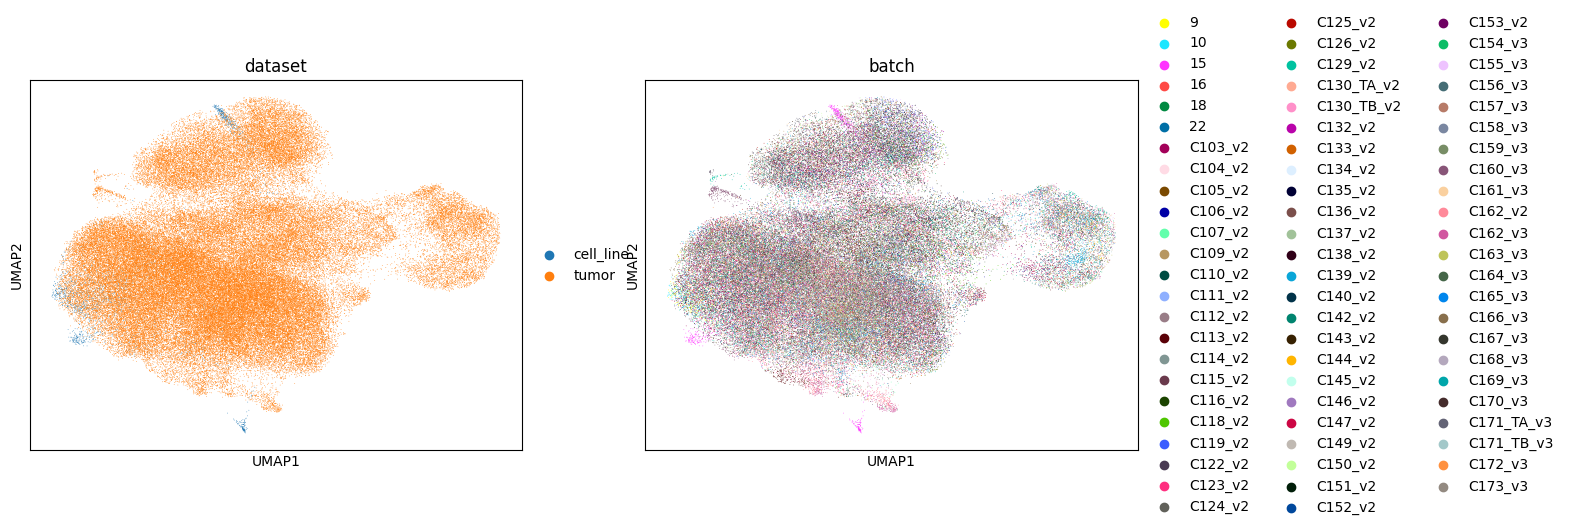

In [22]:
sc.pl.umap(adata, color=["dataset","batch"])

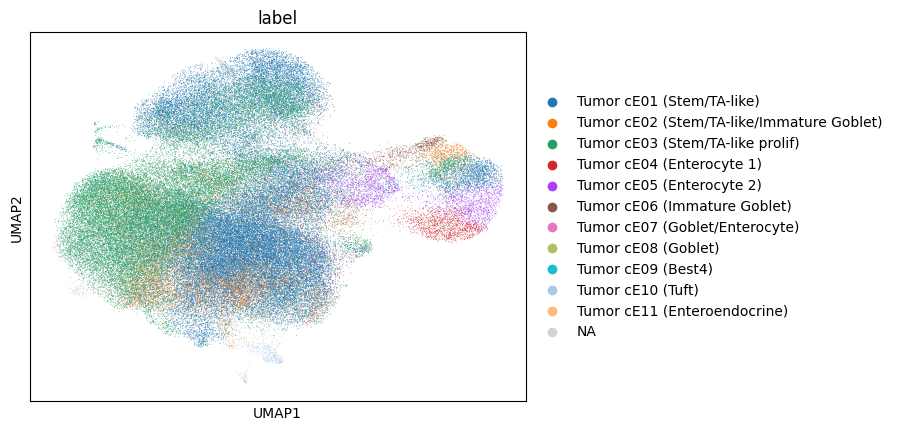

In [23]:
sc.pl.umap(adata, color="label")

At a quick glance, it looks like the integration and batch effect correction worked well. Across all the batches in the tumor data, the cells mix in the latent space and the cell subtypes (`label`) cluster somewhat together. However, the cell line dataset does not seem to integrate too well into the tumor data. Most likely due to the biological differences more than the technical variations. 


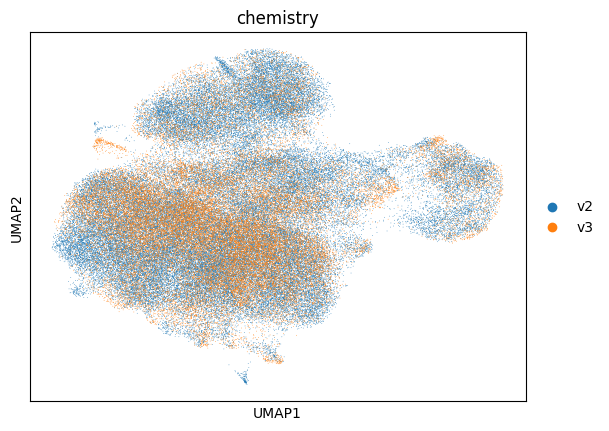

In [24]:
sc.pl.umap(adata, color="chemistry")

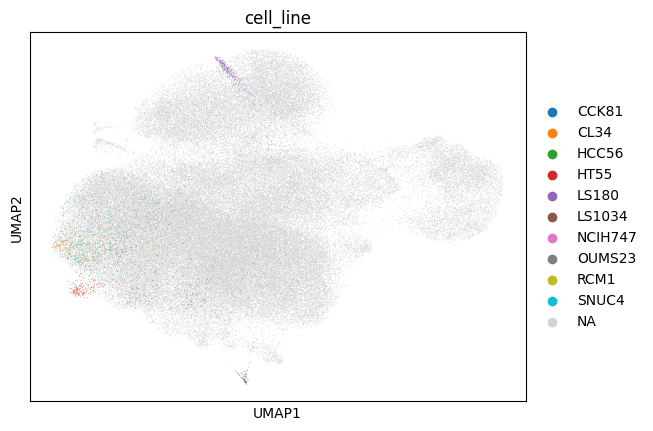

In [25]:
sc.pl.umap(adata, color="cell_line")

### Clustering on the scVI latent space

In [37]:
SCVI_LEIDEN_KEY = "leiden_scVI"
sc.tl.leiden(adata, key_added=SCVI_LEIDEN_KEY, resolution=0.5, flavor="igraph", directed=False)

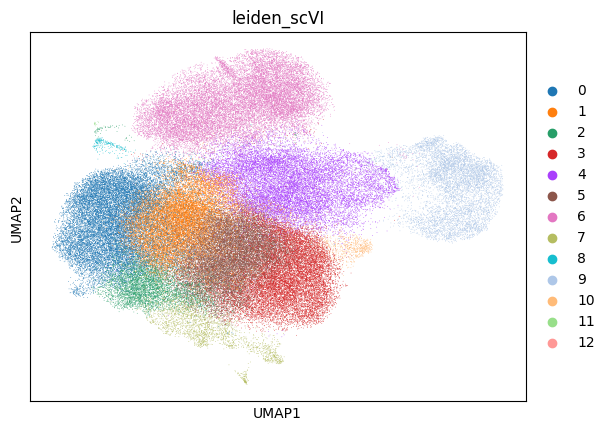

In [38]:
sc.pl.umap(adata, color=SCVI_LEIDEN_KEY)